## 2. CNN Dataset and DataLoaders

Load RGB images from the existing driver-based training dataset.

Use the saved cross-validation folds to prevent driver overlap.

Begin with the original CNN preprocessing configuration
before introducing augmentation or architecture changes.

In [3]:
import torch
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold

# 1. Project directory
ROOT = Path("..")

# 2. Random seed
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

# 3. Select computing device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# 4. Load driver-based dataset splits
train_df = pd.read_csv(
    ROOT / "data/splits/driver_based/train.csv"
)

val_df = pd.read_csv(
    ROOT / "data/splits/driver_based/val.csv"
)

# 5. Create 4-fold driver-independent cross-validation
cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED
)

folds = list(
    cv.split(
        np.zeros(len(train_df)),
        train_df["classname"],
        groups=train_df["subject"]
    )
)

# 6. Verify no overlapping drivers
assert set(train_df["subject"]).isdisjoint(
    set(val_df["subject"])
)

for train_idx, valid_idx in folds:
    assert set(train_df.iloc[train_idx]["subject"]).isdisjoint(
        set(train_df.iloc[valid_idx]["subject"])
    )

# 7. Display information
print("Device:", device)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training drivers:", train_df["subject"].nunique())
print("Validation drivers:", val_df["subject"].nunique())
print("Cross-validation folds:", len(folds))

print("\nSetup completed successfully!")

Device: cuda
Training images: 15732
Validation images: 3603
Training drivers: 18
Validation drivers: 4
Cross-validation folds: 4

Setup completed successfully!


## 2. Load and Verify Image Paths

Locate the original State Farm images and verify that
all training and validation images are accessible.

CNNs will learn directly from RGB images rather than
precomputed HOG features.

In [4]:
from PIL import Image

# 1. Possible locations of original images
image_candidates = [
    ROOT / "data/raw/imgs/train",
    ROOT / "data/raw/state-farm-distracted-driver-detection/imgs/train"
]

# 2. Find the correct directory
image_root = next(
    (
        p for p in image_candidates
        if (p / train_df.iloc[0]["classname"] /
            train_df.iloc[0]["img"]).is_file()
    ),
    None
)

assert image_root is not None, "Image directory not found!"

# 3. Verify all images exist
for name, df in [("Training", train_df), ("Validation", val_df)]:

    missing = sum(
        not (image_root / row.classname / row.img).is_file()
        for row in df.itertuples(index=False)
    )

    print(f"{name} images: {len(df)}")
    print(f"Missing images: {missing}")

    assert missing == 0, f"{name} has missing images!"

# 4. Inspect one original image
sample = train_df.iloc[0]
sample_path = image_root / sample["classname"] / sample["img"]

with Image.open(sample_path) as img:
    print("\nOriginal image dimensions:", img.size)
    print("Image format:", img.mode)

print("Image directory:", image_root)
print("\nAll images verified successfully!")

Training images: 15732
Missing images: 0
Validation images: 3603
Missing images: 0

Original image dimensions: (640, 480)
Image format: RGB
Image directory: ../data/raw/imgs/train

All images verified successfully!


## 3. Image Preprocessing

Resize original RGB images from 640×480 to 256×192 while preserving the 4:3 aspect ratio.

Convert images into PyTorch tensors for CNN training.

In [5]:
from torchvision import transforms

# Fixed CNN input resolution (width × height)
IMAGE_WIDTH = 256
IMAGE_HEIGHT = 192

# Resize images and convert them into tensors
transform = transforms.Compose([
    transforms.Resize((IMAGE_HEIGHT, IMAGE_WIDTH)),
    transforms.ToTensor()
])

# Test preprocessing on one original image
with Image.open(sample_path) as img:
    image = transform(img.convert("RGB"))

print("Processed image shape:", image.shape)
print("Pixel range:", image.min().item(), image.max().item())

Processed image shape: torch.Size([3, 192, 256])
Pixel range: 0.0 1.0


## 4. PyTorch Dataset and DataLoaders

Create a custom Dataset to load images and their corresponding labels.

- Load RGB images and apply preprocessing.
- Convert class labels (c0–c9) into integers (0–9).
- Use Fold 1 for initial CNN development.
- Create batches of 32 images.
- Ensure training and evaluation drivers do not overlap.

In [7]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# ==========================================
# 1. Create PyTorch Dataset
# ==========================================

class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        row = self.data.iloc[idx]

        # Locate original image
        image_path = (
            image_root /
            row["classname"] /
            row["img"]
        )

        # Load and preprocess image
        with Image.open(image_path) as img:
            image = self.transform(img.convert("RGB"))

        # Convert class c0-c9 into integer 0-9
        label = int(row["classname"][1:])

        return image, label


# ==========================================
# 2. Select Cross-Validation Fold 1
# ==========================================

train_idx, valid_idx = folds[0]

fold_train_df = train_df.iloc[train_idx].copy()
fold_valid_df = train_df.iloc[valid_idx].copy()

# Verify driver separation
assert set(fold_train_df["subject"]).isdisjoint(
    set(fold_valid_df["subject"])
)


# ==========================================
# 3. Create Datasets
# ==========================================

train_dataset = DriverDataset(
    fold_train_df,
    transform
)

valid_dataset = DriverDataset(
    fold_valid_df,
    transform
)


# ==========================================
# 4. Create DataLoaders
# ==========================================

BATCH_SIZE = 32
# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

# Validation DataLoader
valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


# ==========================================
# 5. Verify DataLoaders
# ==========================================

images, targets = next(iter(train_loader))

print("Fold 1 ready!")

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))

print("Training drivers:", fold_train_df["subject"].nunique())
print("Validation drivers:", fold_valid_df["subject"].nunique())

print("\nImage batch shape:", images.shape)
print("Label batch shape:", targets.shape)

print("Image dtype:", images.dtype)
print("Label values:", targets.unique().tolist())

print("\nDataLoaders created successfully!")

Fold 1 ready!
Training images: 11492
Validation images: 4240
Training drivers: 13
Validation drivers: 5

Image batch shape: torch.Size([32, 3, 192, 256])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

DataLoaders created successfully!


## 5. CNN Architecture — Baseline

Implement a convolutional neural network from scratch.

Architecture:
- Three convolutional blocks with 32, 64, and 128 filters.
- ReLU activation and MaxPooling.
- Adaptive Average Pooling.
- Fully connected classification layer with 10 outputs.

The model is randomly initialized without pretrained weights.

Batch Normalization and Dropout will be investigated
in later optimization and ablation experiments.

In [8]:
import torch
import torch.nn as nn

# ==========================================
# 1. Define CNN Architecture
# ==========================================

class DriverCNN(nn.Module):

    def __init__(self, num_classes=10):
        super().__init__()

        # Extract visual features
        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # Convert feature maps into 128 features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # Classify into 10 activities
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)

        return x


# ==========================================
# 2. Initialize Model
# ==========================================

model = DriverCNN(num_classes=10).to(device)


# ==========================================
# 3. Count Trainable Parameters
# ==========================================

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)


# ==========================================
# 4. Test Forward Pass
# ==========================================

model.eval()

with torch.no_grad():

    test_images = images.to(device)

    outputs = model(test_images)

print("\nInput shape:", test_images.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (32, 10)

print("\nCNN architecture verified successfully!")

Total parameters: 94538
Trainable parameters: 94538

Input shape: torch.Size([32, 3, 192, 256])
Output shape: torch.Size([32, 10])

CNN architecture verified successfully!


## 6. Training and Early-Stopping Split

Create a driver-independent early-stopping subset within Fold 1.

- Training data: Update CNN parameters.
- Early-stopping data: Monitor overfitting and select the training epoch.
- Outer CV evaluation data: Evaluate the model after training.

No driver can appear in multiple subsets.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader

# 1. Create inner driver-independent split
inner_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED + 1
)

inner_train_idx, stop_idx = next(
    inner_cv.split(
        fold_train_df,
        fold_train_df["classname"],
        groups=fold_train_df["subject"]
    )
)

# 2. Separate training and early-stopping images
inner_train_df = fold_train_df.iloc[inner_train_idx].copy()
stop_df = fold_train_df.iloc[stop_idx].copy()

# 3. Verify no driver overlap
train_drivers = set(inner_train_df["subject"])
stop_drivers = set(stop_df["subject"])
outer_drivers = set(fold_valid_df["subject"])

assert train_drivers.isdisjoint(stop_drivers)
assert train_drivers.isdisjoint(outer_drivers)
assert stop_drivers.isdisjoint(outer_drivers)

# 4. Create datasets
train_dataset = DriverDataset(inner_train_df, transform)
stop_dataset = DriverDataset(stop_df, transform)

# 5. Update training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

# 6. Create early-stopping DataLoader
stop_loader = DataLoader(
    stop_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

# 7. Display split information
print("Training images:", len(train_dataset))
print("Early-stopping images:", len(stop_dataset))
print("Outer CV evaluation images:", len(valid_dataset))

print("\nTraining drivers:", sorted(train_drivers))
print("Early-stopping drivers:", sorted(stop_drivers))
print("Outer CV drivers:", sorted(outer_drivers))

print("\nDriver overlap: 0")
print("Early-stopping split created successfully!")

Training images: 8825
Early-stopping images: 2667
Outer CV evaluation images: 4240

Training drivers: ['p002', 'p021', 'p022', 'p035', 'p041', 'p049', 'p052', 'p056', 'p061', 'p081']
Early-stopping drivers: ['p024', 'p039', 'p050']
Outer CV drivers: ['p015', 'p042', 'p051', 'p064', 'p066']

Driver overlap: 0
Early-stopping split created successfully!


## 7. CNN Training Configuration — Baseline

Configure the first CNN experiment using Fold 1.

**Baseline hyperparameters:**
- Model: Custom CNN (94,538 parameters)
- Image resolution: 256×192 RGB
- Batch size: 32
- Optimizer: Adam
- Learning rate: 0.001
- Loss function: CrossEntropyLoss
- Maximum epochs: 20
- Early-stopping patience: 5
- Random seed: 42

**Evaluation protocol:**
- Inner training: 10 drivers
- Early stopping: 3 drivers
- Outer cross-validation evaluation: 5 drivers

Early stopping monitors loss on the three held-out stopping drivers.

The outer evaluation drivers are not used for training or checkpoint selection.

Save hyperparameters, training metrics, execution times, and model checkpoints for reproducibility.

In [10]:
import torch
import torch.nn as nn
import numpy as np
import json
import random
from pathlib import Path

# ==========================================
# 1. Set reproducibility seed
# ==========================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ==========================================
# 2. Configure baseline hyperparameters
# ==========================================

LEARNING_RATE = 0.001
EPOCHS = 20
PATIENCE = 5
WEIGHT_DECAY = 0.0

# BATCH_SIZE = 32 (already defined in Step 4)


# ==========================================
# 3. Initialize a fresh CNN
# ==========================================

model = DriverCNN(num_classes=10).to(device)


# ==========================================
# 4. Define loss function
# ==========================================

criterion = nn.CrossEntropyLoss()


# ==========================================
# 5. Define optimizer
# ==========================================

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ==========================================
# 6. Create experiment directories
# ==========================================

experiment_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "cnn_from_scratch/baseline/fold_1"
)

checkpoint_dir = (
    ROOT / "models/deep_learning/driver_based/"
    "cnn_from_scratch/baseline/fold_1"
)

experiment_dir.mkdir(parents=True, exist_ok=True)
checkpoint_dir.mkdir(parents=True, exist_ok=True)


# ==========================================
# 7. Save experiment configuration
# ==========================================

config = {
    "experiment": "CNN_Scratch_Baseline",
    "fold": 1,

    "architecture": {
        "model": "DriverCNN",
        "pretrained": False,
        "parameters": sum(
            p.numel() for p in model.parameters()
        )
    },

    "hyperparameters": {
        "image_width": IMAGE_WIDTH,
        "image_height": IMAGE_HEIGHT,
        "batch_size": BATCH_SIZE,
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "loss_function": "CrossEntropyLoss",
        "max_epochs": EPOCHS,
        "early_stopping_patience": PATIENCE,
        "early_stopping_metric": "loss",
        "augmentation": False,
        "random_seed": SEED
    },

    "dataset": {
        "training_images": len(train_dataset),
        "early_stopping_images": len(stop_dataset),
        "outer_cv_images": len(valid_dataset),

        "training_drivers": sorted(train_drivers),
        "early_stopping_drivers": sorted(stop_drivers),
        "outer_cv_drivers": sorted(outer_drivers)
    },

    "environment": {
        "pytorch_version": torch.__version__,
        "device": str(device),
        "gpu": (
            torch.cuda.get_device_name(0)
            if device.type == "cuda"
            else None
        )
    }
}

config_path = experiment_dir / "configuration.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)


# ==========================================
# 8. Verify configuration
# ==========================================

print("CNN Training Configuration")
print("--------------------------")

print("Device:", device)
print("Optimizer:", optimizer.__class__.__name__)
print("Loss:", criterion.__class__.__name__)

print("\nLearning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)

print("\nMaximum epochs:", EPOCHS)
print("Early-stopping patience:", PATIENCE)

print("\nTraining images:", len(train_dataset))
print("Early-stopping images:", len(stop_dataset))
print("Outer CV images:", len(valid_dataset))

print("\nTrainable parameters:", config["architecture"]["parameters"])

print("\nConfiguration saved:", config_path)
print("\nReady for CNN training!")

CNN Training Configuration
--------------------------
Device: cuda
Optimizer: Adam
Loss: CrossEntropyLoss

Learning rate: 0.001
Weight decay: 0.0
Batch size: 32

Maximum epochs: 20
Early-stopping patience: 5

Training images: 8825
Early-stopping images: 2667
Outer CV images: 4240

Trainable parameters: 94538

Configuration saved: ../results/deep_learning/driver_based/cnn_from_scratch/baseline/fold_1/configuration.json

Ready for CNN training!


## 8. CNN Baseline Training — Fold 1

Train the randomly initialized CNN using Adam and CrossEntropyLoss.

### Training procedure
- Train on 10 drivers.
- Monitor performance on 3 early-stopping drivers.
- Use a maximum of 20 epochs.
- Stop after 5 epochs without improvement in early-stopping loss.
- Restore the best checkpoint.

### Experiment documentation
Record:
- Training and early-stopping loss
- Accuracy and Macro-F1
- Execution time per epoch
- Total training time
- Best epoch and checkpoint
- Maximum GPU memory consumption

The 5 outer cross-validation drivers remain untouched.

In [11]:
import time
import json
import pandas as pd
import torch

from sklearn.metrics import f1_score

# ==========================================
# 1. Function to train or evaluate one epoch
# ==========================================

def run_epoch(loader, training=True):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    all_targets = []
    all_predictions = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for batch_images, batch_labels in loader:

        # Move batch to GPU
        batch_images = batch_images.to(
            device, non_blocking=True
        )

        batch_labels = batch_labels.to(
            device, non_blocking=True
        )

        # Train only when training=True
        with torch.set_grad_enabled(training):

            outputs = model(batch_images)

            loss = criterion(
                outputs, batch_labels
            )

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        # Calculate predictions
        predictions = outputs.argmax(dim=1)

        batch_size = batch_labels.size(0)

        total_loss += loss.item() * batch_size

        total_correct += (
            predictions == batch_labels
        ).sum().item()

        total_samples += batch_size

        all_targets.extend(
            batch_labels.cpu().tolist()
        )

        all_predictions.extend(
            predictions.cpu().tolist()
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    return {
        "loss": total_loss / total_samples,

        "accuracy": total_correct / total_samples,

        "macro_f1": f1_score(
            all_targets,
            all_predictions,
            labels=list(range(10)),
            average="macro",
            zero_division=0
        ),

        "time_seconds": elapsed
    }


# ==========================================
# 2. Prepare training experiment
# ==========================================

history = []

best_stop_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

checkpoint_path = checkpoint_dir / "best_model.pt"

history_path = experiment_dir / "training_history.csv"
summary_path = experiment_dir / "training_summary.json"

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

total_start = time.perf_counter()


# ==========================================
# 3. Training loop
# ==========================================

for epoch in range(1, EPOCHS + 1):

    # Train using inner training drivers
    train_metrics = run_epoch(
        train_loader,
        training=True
    )

    # Evaluate using early-stopping drivers
    stop_metrics = run_epoch(
        stop_loader,
        training=False
    )

    # Save all metrics from this epoch
    epoch_record = {
        "epoch": epoch,

        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],

        "stop_loss": stop_metrics["loss"],
        "stop_accuracy": stop_metrics["accuracy"],
        "stop_macro_f1": stop_metrics["macro_f1"],

        "train_time_seconds": train_metrics["time_seconds"],
        "stop_time_seconds": stop_metrics["time_seconds"],

        "epoch_time_seconds": (
            train_metrics["time_seconds"]
            + stop_metrics["time_seconds"]
        )
    }

    history.append(epoch_record)

    # Save progress after every epoch
    pd.DataFrame(history).to_csv(
        history_path,
        index=False
    )

    # ======================================
    # 4. Early stopping
    # ======================================

    if stop_metrics["loss"] < best_stop_loss - 1e-4:

        best_stop_loss = stop_metrics["loss"]
        best_epoch = epoch

        epochs_without_improvement = 0

        # Save best model weights
        torch.save(
            model.state_dict(),
            checkpoint_path
        )

    else:
        epochs_without_improvement += 1

    # ======================================
    # 5. Print epoch results
    # ======================================

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Acc: {train_metrics['accuracy']:.4f} | "
        f"Stop Acc: {stop_metrics['accuracy']:.4f} | "
        f"Stop F1: {stop_metrics['macro_f1']:.4f} | "
        f"Stop Loss: {stop_metrics['loss']:.4f} | "
        f"Time: {epoch_record['epoch_time_seconds']:.1f}s",
        flush=True
    )

    # Stop if no improvement
    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping triggered at epoch {epoch}"
        )

        break


# ==========================================
# 6. Restore best checkpoint
# ==========================================

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()


# ==========================================
# 7. Calculate final execution information
# ==========================================

if device.type == "cuda":
    torch.cuda.synchronize()

total_time = time.perf_counter() - total_start

peak_gpu_memory = (
    torch.cuda.max_memory_allocated() / (1024 ** 2)
    if device.type == "cuda"
    else None
)

history_df = pd.DataFrame(history)

best_record = history_df.loc[
    history_df["epoch"] == best_epoch
].iloc[0]


# ==========================================
# 8. Save training summary
# ==========================================

summary = {
    "experiment": "CNN_Scratch_Baseline",
    "fold": 1,

    "epochs_completed": len(history),
    "best_epoch": best_epoch,

    "best_stop_loss": float(best_stop_loss),
    "best_stop_accuracy": float(
        best_record["stop_accuracy"]
    ),
    "best_stop_macro_f1": float(
        best_record["stop_macro_f1"]
    ),

    "total_training_seconds": float(total_time),

    "peak_gpu_memory_mb": (
        float(peak_gpu_memory)
        if peak_gpu_memory is not None
        else None
    ),

    "early_stopped": len(history) < EPOCHS,
    "checkpoint": str(checkpoint_path),
    "history_csv": str(history_path)
}

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)


# ==========================================
# 9. Display final training results
# ==========================================

print("\n" + "=" * 45)
print("CNN BASELINE — FOLD 1 TRAINING COMPLETED")
print("=" * 45)

print("Epochs completed:", len(history))
print("Best epoch:", best_epoch)

print(f"Best stopping loss: {best_stop_loss:.4f}")

print(
    f"Best stopping accuracy: "
    f"{summary['best_stop_accuracy']:.4f}"
)

print(
    f"Best stopping Macro-F1: "
    f"{summary['best_stop_macro_f1']:.4f}"
)

print(f"\nTotal execution time: {total_time:.2f} seconds")

print("Peak GPU memory (MB):", peak_gpu_memory)

print("\nCheckpoint saved:", checkpoint_path)
print("Training history saved:", history_path)
print("Summary saved:", summary_path)

Epoch 01/20 | Train Acc: 0.1036 | Stop Acc: 0.0885 | Stop F1: 0.0292 | Stop Loss: 2.3015 | Time: 23.1s
Epoch 02/20 | Train Acc: 0.1104 | Stop Acc: 0.0907 | Stop F1: 0.0302 | Stop Loss: 2.3029 | Time: 22.9s
Epoch 03/20 | Train Acc: 0.1322 | Stop Acc: 0.1279 | Stop F1: 0.0529 | Stop Loss: 2.2844 | Time: 23.0s
Epoch 04/20 | Train Acc: 0.1760 | Stop Acc: 0.1549 | Stop F1: 0.0650 | Stop Loss: 2.1759 | Time: 23.1s
Epoch 05/20 | Train Acc: 0.2682 | Stop Acc: 0.1819 | Stop F1: 0.1464 | Stop Loss: 2.1985 | Time: 22.9s
Epoch 06/20 | Train Acc: 0.3566 | Stop Acc: 0.3011 | Stop F1: 0.2453 | Stop Loss: 2.0299 | Time: 22.7s
Epoch 07/20 | Train Acc: 0.4291 | Stop Acc: 0.2538 | Stop F1: 0.2387 | Stop Loss: 2.1973 | Time: 22.2s
Epoch 08/20 | Train Acc: 0.5106 | Stop Acc: 0.2921 | Stop F1: 0.2686 | Stop Loss: 1.9800 | Time: 22.8s
Epoch 09/20 | Train Acc: 0.5622 | Stop Acc: 0.3236 | Stop F1: 0.2652 | Stop Loss: 2.0858 | Time: 22.7s
Epoch 10/20 | Train Acc: 0.6136 | Stop Acc: 0.3213 | Stop F1: 0.3201 | St

## 9. Training Curves — Fold 1

Analyze training and early-stopping performance.

- Compare training and early-stopping loss.
- Compare training and early-stopping accuracy.
- Identify signs of overfitting.
- Visualize the checkpoint selected by early stopping.

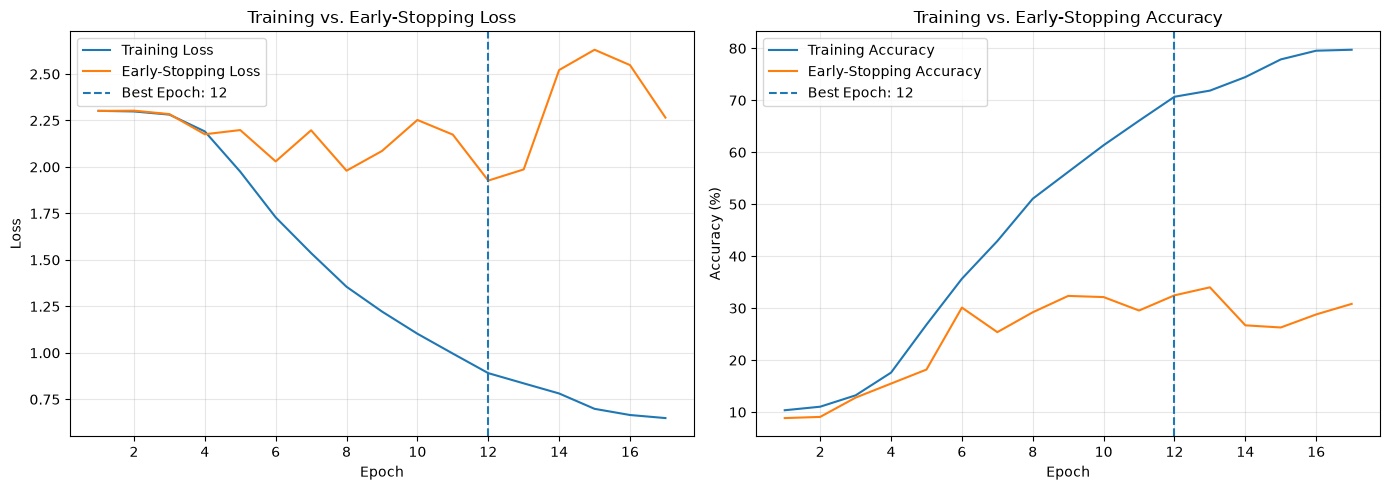

Training curves saved: ../results/deep_learning/driver_based/cnn_from_scratch/baseline/fold_1/training_curves.png


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import json

# 1. Load saved training history
history_df = pd.read_csv(
    experiment_dir / "training_history.csv"
)

# 2. Load saved training summary
with open(experiment_dir / "training_summary.json") as f:
    summary = json.load(f)

best_epoch = summary["best_epoch"]

# 3. Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss comparison
axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["stop_loss"],
    label="Early-Stopping Loss"
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

axes[0].set_title("Training vs. Early-Stopping Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy comparison
axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    label="Training Accuracy"
)

axes[1].plot(
    history_df["epoch"],
    history_df["stop_accuracy"] * 100,
    label="Early-Stopping Accuracy"
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

axes[1].set_title("Training vs. Early-Stopping Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# 4. Save figure
save_path = experiment_dir / "training_curves.png"

plt.savefig(save_path, dpi=200, bbox_inches="tight")

plt.show()

print("Training curves saved:", save_path)

## 10. Outer Cross-Validation Evaluation — Fold 1

Evaluate the CNN checkpoint selected at epoch 12.

- Evaluation images: 4,240
- Evaluation drivers: 5
- No additional training
- No checkpoint selection using outer CV data

Record accuracy, Macro-F1, inference time, and evaluation loss.

In [13]:
import json
import torch

# ==========================================
# 1. Load the best saved checkpoint
# ==========================================

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

# ==========================================
# 2. Verify evaluation dataset
# ==========================================

assert len(valid_loader.dataset) == len(fold_valid_df)

assert set(fold_train_df["subject"]).isdisjoint(
    set(fold_valid_df["subject"])
)

print("Outer CV images:", len(valid_loader.dataset))
print("Outer CV drivers:", fold_valid_df["subject"].nunique())
print("Best checkpoint epoch:", best_epoch)

# ==========================================
# 3. Evaluate without training
# ==========================================

cv_metrics = run_epoch(
    valid_loader,
    training=False
)

# ==========================================
# 4. Save evaluation results
# ==========================================

cv_results = {
    "model": "CNN_From_Scratch_Baseline",
    "fold": 1,
    "best_epoch": int(best_epoch),
    "evaluation_images": len(valid_loader.dataset),
    "evaluation_drivers": sorted(
        fold_valid_df["subject"].unique().tolist()
    ),
    "accuracy": float(cv_metrics["accuracy"]),
    "macro_f1": float(cv_metrics["macro_f1"]),
    "loss": float(cv_metrics["loss"]),
    "evaluation_time_seconds": float(
        cv_metrics["time_seconds"]
    )
}

save_path = experiment_dir / "outer_cv_results.json"

with open(save_path, "w") as f:
    json.dump(cv_results, f, indent=4)

# ==========================================
# 5. Display results
# ==========================================

print("\nCNN Baseline — Fold 1 Results")
print("-" * 40)

print(f"Accuracy: {cv_results['accuracy']:.4f}")
print(f"Macro-F1: {cv_results['macro_f1']:.4f}")
print(f"Loss: {cv_results['loss']:.4f}")

print(
    f"Evaluation time: "
    f"{cv_results['evaluation_time_seconds']:.2f} seconds"
)

print("\nResults saved:", save_path)

Outer CV images: 4240
Outer CV drivers: 5
Best checkpoint epoch: 12

CNN Baseline — Fold 1 Results
----------------------------------------
Accuracy: 0.3733
Macro-F1: 0.3492
Loss: 1.7959
Evaluation time: 7.28 seconds

Results saved: ../results/deep_learning/driver_based/cnn_from_scratch/baseline/fold_1/outer_cv_results.json


## 11. CNN Baseline — Remaining Cross-Validation Folds

Train an independent CNN on each cross-validation fold.

For every fold:
- Initialize a fresh CNN.
- Create a driver-independent early-stopping split.
- Train using the same baseline hyperparameters.
- Select the best checkpoint using early-stopping loss.
- Evaluate on the outer cross-validation drivers.
- Save training history, configuration, checkpoint, metrics, and runtimes.

Each fold is evaluated independently to measure generalization stability.

In [17]:
import time
import json
import random
import numpy as np
import pandas as pd
import torch

from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader

# ==========================================
# 1. Select the fold
# ==========================================

FOLD_ID = 4

assert FOLD_ID in [2, 3, 4]


# ==========================================
# 2. Reproducibility
# ==========================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)


# ==========================================
# 3. Select outer CV fold
# ==========================================

outer_train_idx, outer_valid_idx = folds[FOLD_ID - 1]

outer_train_df = train_df.iloc[outer_train_idx].copy()
outer_valid_df = train_df.iloc[outer_valid_idx].copy()


# ==========================================
# 4. Create inner early-stopping split
# ==========================================

inner_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED + 1
)

inner_train_idx, stop_idx = next(
    inner_cv.split(
        outer_train_df,
        outer_train_df["classname"],
        groups=outer_train_df["subject"]
    )
)

inner_train_df = outer_train_df.iloc[inner_train_idx].copy()
stop_df = outer_train_df.iloc[stop_idx].copy()

# Verify all three sets contain different drivers
train_drivers = set(inner_train_df["subject"])
stop_drivers = set(stop_df["subject"])
outer_drivers = set(outer_valid_df["subject"])

assert train_drivers.isdisjoint(stop_drivers)
assert train_drivers.isdisjoint(outer_drivers)
assert stop_drivers.isdisjoint(outer_drivers)

# Keep the reserved validation drivers separate
assert set(train_df["subject"]).isdisjoint(
    set(val_df["subject"])
)


# ==========================================
# 5. Create datasets and loaders
# ==========================================

train_loader = DataLoader(
    DriverDataset(inner_train_df, transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

stop_loader = DataLoader(
    DriverDataset(stop_df, transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

outer_loader = DataLoader(
    DriverDataset(outer_valid_df, transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


# ==========================================
# 6. Initialize a NEW model
# ==========================================

model = DriverCNN(num_classes=10).to(device)

criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ==========================================
# 7. Experiment directories
# ==========================================

exp_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "cnn_from_scratch/baseline" / f"fold_{FOLD_ID}"
)

ckpt_dir = (
    ROOT / "models/deep_learning/driver_based/"
    "cnn_from_scratch/baseline" / f"fold_{FOLD_ID}"
)

exp_dir.mkdir(parents=True, exist_ok=True)
ckpt_dir.mkdir(parents=True, exist_ok=True)

checkpoint = ckpt_dir / "best_model.pt"


# ==========================================
# 8. Save configuration
# ==========================================

fold_config = {
    "fold": FOLD_ID,
    "model": "DriverCNN",
    "parameters": sum(p.numel() for p in model.parameters()),
    "image_size": [IMAGE_WIDTH, IMAGE_HEIGHT],
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "max_epochs": EPOCHS,
    "patience": PATIENCE,
    "random_seed": SEED,
    "training_images": len(inner_train_df),
    "stopping_images": len(stop_df),
    "outer_cv_images": len(outer_valid_df),
    "training_drivers": sorted(train_drivers),
    "stopping_drivers": sorted(stop_drivers),
    "outer_cv_drivers": sorted(outer_drivers)
}

with open(exp_dir / "configuration.json", "w") as f:
    json.dump(fold_config, f, indent=4)


# ==========================================
# 9. Train CNN
# ==========================================

history = []

best_loss = float("inf")
best_epoch = 0
no_improvement = 0

start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):

    train_metrics = run_epoch(train_loader, training=True)
    stop_metrics = run_epoch(stop_loader, training=False)

    record = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "stop_loss": stop_metrics["loss"],
        "stop_accuracy": stop_metrics["accuracy"],
        "stop_macro_f1": stop_metrics["macro_f1"],
        "train_time_seconds": train_metrics["time_seconds"],
        "stop_time_seconds": stop_metrics["time_seconds"]
    }

    history.append(record)

    # Save progress after each epoch
    pd.DataFrame(history).to_csv(
        exp_dir / "training_history.csv",
        index=False
    )

    # Early stopping
    if stop_metrics["loss"] < best_loss - 1e-4:

        best_loss = stop_metrics["loss"]
        best_epoch = epoch
        no_improvement = 0

        torch.save(model.state_dict(), checkpoint)

    else:
        no_improvement += 1

    print(
        f"Fold {FOLD_ID} | Epoch {epoch:02d} | "
        f"Train Acc: {train_metrics['accuracy']:.4f} | "
        f"Stop Acc: {stop_metrics['accuracy']:.4f} | "
        f"Stop F1: {stop_metrics['macro_f1']:.4f}",
        flush=True
    )

    if no_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break


# ==========================================
# 10. Restore best model
# ==========================================

model.load_state_dict(
    torch.load(
        checkpoint,
        map_location=device,
        weights_only=True
    )
)

model.eval()

training_time = time.perf_counter() - start


# ==========================================
# 11. Evaluate outer CV fold
# ==========================================

cv_metrics = run_epoch(
    outer_loader,
    training=False
)


# ==========================================
# 12. Save training summary
# ==========================================

best_record = history[best_epoch - 1]

training_summary = {
    "fold": FOLD_ID,
    "epochs_completed": len(history),
    "best_epoch": best_epoch,
    "best_stop_loss": float(best_loss),
    "best_stop_accuracy": float(best_record["stop_accuracy"]),
    "best_stop_macro_f1": float(best_record["stop_macro_f1"]),
    "total_training_seconds": float(training_time),
    "checkpoint": str(checkpoint)
}

with open(exp_dir / "training_summary.json", "w") as f:
    json.dump(training_summary, f, indent=4)


# ==========================================
# 13. Save outer CV results
# ==========================================

cv_results = {
    "model": "CNN_From_Scratch_Baseline",
    "fold": FOLD_ID,
    "best_epoch": best_epoch,
    "evaluation_images": len(outer_valid_df),
    "evaluation_drivers": sorted(outer_drivers),
    "accuracy": float(cv_metrics["accuracy"]),
    "macro_f1": float(cv_metrics["macro_f1"]),
    "loss": float(cv_metrics["loss"]),
    "evaluation_time_seconds": float(
        cv_metrics["time_seconds"]
    ),
    "total_training_seconds": float(training_time)
}

with open(exp_dir / "outer_cv_results.json", "w") as f:
    json.dump(cv_results, f, indent=4)


# ==========================================
# 14. Display results
# ==========================================

print(f"\nCNN Baseline — Fold {FOLD_ID}")
print("=" * 40)

print("Best epoch:", best_epoch)
print("Epochs completed:", len(history))

print(f"Accuracy: {cv_metrics['accuracy']:.4f}")
print(f"Macro-F1: {cv_metrics['macro_f1']:.4f}")
print(f"Loss: {cv_metrics['loss']:.4f}")

print(f"Training time: {training_time:.2f} seconds")
print(f"Evaluation time: {cv_metrics['time_seconds']:.2f} seconds")

print("\nResults saved:", exp_dir)

Fold 4 | Epoch 01 | Train Acc: 0.1027 | Stop Acc: 0.1110 | Stop F1: 0.0200
Fold 4 | Epoch 02 | Train Acc: 0.1168 | Stop Acc: 0.1110 | Stop F1: 0.0200
Fold 4 | Epoch 03 | Train Acc: 0.1411 | Stop Acc: 0.1156 | Stop F1: 0.0316
Fold 4 | Epoch 04 | Train Acc: 0.2357 | Stop Acc: 0.1811 | Stop F1: 0.1394
Fold 4 | Epoch 05 | Train Acc: 0.3152 | Stop Acc: 0.2229 | Stop F1: 0.1449
Fold 4 | Epoch 06 | Train Acc: 0.3984 | Stop Acc: 0.2542 | Stop F1: 0.2136
Fold 4 | Epoch 07 | Train Acc: 0.4796 | Stop Acc: 0.3213 | Stop F1: 0.3076
Fold 4 | Epoch 08 | Train Acc: 0.5564 | Stop Acc: 0.3708 | Stop F1: 0.3730
Fold 4 | Epoch 09 | Train Acc: 0.6122 | Stop Acc: 0.3645 | Stop F1: 0.3582
Fold 4 | Epoch 10 | Train Acc: 0.6496 | Stop Acc: 0.3512 | Stop F1: 0.3577
Early stopping triggered.

CNN Baseline — Fold 4
Best epoch: 5
Epochs completed: 10
Accuracy: 0.2231
Macro-F1: 0.1489
Loss: 2.4509
Training time: 245.27 seconds
Evaluation time: 6.45 seconds

Results saved: ../results/deep_learning/driver_based/cnn_f

In [16]:
import json

# Load saved Fold 3 results
result_path = (
    ROOT / "results/deep_learning/driver_based/"
    "cnn_from_scratch/baseline/fold_3/outer_cv_results.json"
)

with open(result_path) as f:
    result = json.load(f)

print("CNN Baseline — Fold 3")
print("-" * 35)

print("Best epoch:", result["best_epoch"])
print(f"Accuracy: {result['accuracy']:.4f}")
print(f"Macro-F1: {result['macro_f1']:.4f}")
print(f"Loss: {result['loss']:.4f}")
print(f"Evaluation time: {result['evaluation_time_seconds']:.2f}s")

CNN Baseline — Fold 3
-----------------------------------
Best epoch: 17
Accuracy: 0.3135
Macro-F1: 0.2933
Loss: 2.0609
Evaluation time: 6.98s


## 12. CNN Baseline — Cross-Validation Summary

Consolidate results from all four driver-independent folds.

Calculate:
- Mean accuracy and standard deviation
- Mean Macro-F1 and standard deviation
- Training and evaluation runtimes
- Best epoch for each fold

Save results for future model comparisons and the presentation.

In [18]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Results directory
baseline_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "cnn_from_scratch/baseline"
)

# 2. Load all four folds
results = []

for fold in range(1, 5):

    fold_dir = baseline_dir / f"fold_{fold}"

    with open(fold_dir / "outer_cv_results.json") as f:
        cv_result = json.load(f)

    with open(fold_dir / "training_summary.json") as f:
        training_result = json.load(f)

    results.append({
        "fold": fold,
        "accuracy": cv_result["accuracy"],
        "macro_f1": cv_result["macro_f1"],
        "loss": cv_result["loss"],
        "best_epoch": cv_result["best_epoch"],
        "training_time_seconds": training_result["total_training_seconds"],
        "evaluation_time_seconds": cv_result["evaluation_time_seconds"]
    })

# 3. Create DataFrame
cv_df = pd.DataFrame(results)

# 4. Calculate statistics
summary = {
    "model": "CNN_From_Scratch_Baseline",
    "resolution": "256x192",
    "cv_folds": 4,
    "mean_accuracy": float(cv_df["accuracy"].mean()),
    "std_accuracy": float(cv_df["accuracy"].std(ddof=1)),
    "mean_macro_f1": float(cv_df["macro_f1"].mean()),
    "std_macro_f1": float(cv_df["macro_f1"].std(ddof=1)),
    "total_training_seconds": float(
        cv_df["training_time_seconds"].sum()
    ),
    "total_evaluation_seconds": float(
        cv_df["evaluation_time_seconds"].sum()
    ),
    "fold_results": results
}

# 5. Save results
cv_df.to_csv(
    baseline_dir / "cv_fold_results.csv",
    index=False
)

with open(baseline_dir / "cv_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

# 6. Display results
print("CNN Baseline — 4-Fold Cross-Validation")
print("=" * 45)

print(cv_df.to_string(index=False))

print(f"\nMean Accuracy: {summary['mean_accuracy']:.4f}")
print(f"Accuracy Std: {summary['std_accuracy']:.4f}")

print(f"\nMean Macro-F1: {summary['mean_macro_f1']:.4f}")
print(f"Macro-F1 Std: {summary['std_macro_f1']:.4f}")

print(
    f"\nTotal training time: "
    f"{summary['total_training_seconds']:.2f} seconds"
)

print("\nCross-validation summary saved!")

CNN Baseline — 4-Fold Cross-Validation
 fold  accuracy  macro_f1     loss  best_epoch  training_time_seconds  evaluation_time_seconds
    1  0.373349  0.349168 1.795931          12             388.185652                 7.277120
    2  0.251585  0.212198 2.179349           6             252.928269                 7.698958
    3  0.313524  0.293305 2.060932          17             475.939161                 6.981275
    4  0.223085  0.148911 2.450866           5             245.269931                 6.450075

Mean Accuracy: 0.2904
Accuracy Std: 0.0670

Mean Macro-F1: 0.2509
Macro-F1 Std: 0.0882

Total training time: 1362.32 seconds

Cross-validation summary saved!


## 13. CNN Baseline — Full Training Dataset

Train the CNN from scratch using all 15,732 training images
from 18 drivers.

Configuration:
- Resolution: 256×192 RGB
- Architecture: Baseline CNN (94,538 parameters)
- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 32
- Epochs: 10
- No early stopping

Evaluate once on the 3,603 reserved validation images
from four unseen drivers.

Save the trained model, training history, metrics,
and execution times.

The final test dataset remains untouched.

In [19]:
import torch
import time
import json
import random
import numpy as np
import pandas as pd

from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# ==========================================
# 1. Configuration
# ==========================================

EPOCHS_FULL = 10
LR_FULL = 0.001

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ==========================================
# 2. Load ALL training images
# ==========================================

full_train_dataset = DriverDataset(train_df, transform)
full_val_dataset = DriverDataset(val_df, transform)

assert set(train_df["subject"]).isdisjoint(
    set(val_df["subject"])
)

full_train_loader = DataLoader(
    full_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

full_val_loader = DataLoader(
    full_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training images:", len(full_train_dataset))
print("Training drivers:", train_df["subject"].nunique())

print("Validation images:", len(full_val_dataset))
print("Validation drivers:", val_df["subject"].nunique())


# ==========================================
# 3. Initialize NEW CNN
# ==========================================

full_model = DriverCNN(num_classes=10).to(device)

full_criterion = torch.nn.CrossEntropyLoss()

full_optimizer = torch.optim.Adam(
    full_model.parameters(),
    lr=LR_FULL
)

# ==========================================
# 4. Create experiment directories
# ==========================================

full_exp_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "cnn_from_scratch/baseline/full_training"
)

full_model_dir = (
    ROOT / "models/deep_learning/driver_based/"
    "cnn_from_scratch/baseline/full_training"
)

full_exp_dir.mkdir(parents=True, exist_ok=True)
full_model_dir.mkdir(parents=True, exist_ok=True)


# ==========================================
# 5. Train CNN on all 18 drivers
# ==========================================

history_full = []

start_total = time.perf_counter()

for epoch in range(1, EPOCHS_FULL + 1):

    full_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    start_epoch = time.perf_counter()

    for batch_images, batch_labels in full_train_loader:

        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        full_optimizer.zero_grad()

        outputs = full_model(batch_images)

        loss = full_criterion(outputs, batch_labels)

        loss.backward()
        full_optimizer.step()

        predictions = outputs.argmax(dim=1)

        running_loss += loss.item() * batch_labels.size(0)

        correct += (
            predictions == batch_labels
        ).sum().item()

        total += batch_labels.size(0)

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_epoch

    train_loss = running_loss / total
    train_accuracy = correct / total

    history_full.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "epoch_time_seconds": epoch_time
    })

    # Save progress after each epoch
    pd.DataFrame(history_full).to_csv(
        full_exp_dir / "training_history.csv",
        index=False
    )

    print(
        f"Epoch {epoch:02d}/{EPOCHS_FULL} | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {train_accuracy:.4f} | "
        f"Time: {epoch_time:.2f}s",
        flush=True
    )

training_time = time.perf_counter() - start_total


# ==========================================
# 6. Save trained model
# ==========================================

model_path = full_model_dir / "cnn_full_training.pt"

torch.save(full_model.state_dict(), model_path)


# ==========================================
# 7. Evaluate on reserved validation drivers
# ==========================================

full_model.eval()

all_true = []
all_pred = []

validation_loss = 0.0
validation_total = 0

start_val = time.perf_counter()

with torch.no_grad():

    for batch_images, batch_labels in full_val_loader:

        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        outputs = full_model(batch_images)

        loss = full_criterion(outputs, batch_labels)

        predictions = outputs.argmax(dim=1)

        validation_loss += (
            loss.item() * batch_labels.size(0)
        )

        validation_total += batch_labels.size(0)

        all_true.extend(batch_labels.cpu().tolist())
        all_pred.extend(predictions.cpu().tolist())

if device.type == "cuda":
    torch.cuda.synchronize()

validation_time = time.perf_counter() - start_val

val_accuracy = accuracy_score(all_true, all_pred)

val_macro_f1 = f1_score(
    all_true,
    all_pred,
    labels=list(range(10)),
    average="macro",
    zero_division=0
)

val_loss = validation_loss / validation_total


# ==========================================
# 8. Save experiment results
# ==========================================

results_full = {
    "model": "CNN_From_Scratch_Baseline",
    "experiment": "Full_Training",
    "training_images": len(full_train_dataset),
    "training_drivers": 18,
    "validation_images": len(full_val_dataset),
    "validation_drivers": 4,
    "resolution": "256x192",
    "epochs": EPOCHS_FULL,
    "learning_rate": LR_FULL,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "seed": SEED,
    "parameters": sum(
        p.numel() for p in full_model.parameters()
    ),
    "training_time_seconds": training_time,
    "validation_time_seconds": validation_time,
    "validation_accuracy": float(val_accuracy),
    "validation_macro_f1": float(val_macro_f1),
    "validation_loss": float(val_loss),
    "model_path": str(model_path)
}

with open(full_exp_dir / "results.json", "w") as f:
    json.dump(results_full, f, indent=4)


# ==========================================
# 9. Display final results
# ==========================================

print("\n" + "=" * 45)
print("CNN FROM SCRATCH — FULL TRAINING RESULTS")
print("=" * 45)

print("Training images:", len(full_train_dataset))
print("Training drivers:", 18)

print(f"\nFinal training accuracy: {train_accuracy:.4f}")

print(f"\nValidation accuracy: {val_accuracy:.4f}")
print(f"Validation Macro-F1: {val_macro_f1:.4f}")
print(f"Validation loss: {val_loss:.4f}")

print(f"\nTraining time: {training_time:.2f}s")
print(f"Validation time: {validation_time:.2f}s")

print("\nModel saved:", model_path)
print("Results saved:", full_exp_dir)

Training images: 15732
Training drivers: 18
Validation images: 3603
Validation drivers: 4
Epoch 01/10 | Loss: 2.3015 | Accuracy: 0.1088 | Time: 31.87s
Epoch 02/10 | Loss: 2.2886 | Accuracy: 0.1275 | Time: 32.10s
Epoch 03/10 | Loss: 2.0521 | Accuracy: 0.2358 | Time: 31.72s
Epoch 04/10 | Loss: 1.7272 | Accuracy: 0.3433 | Time: 32.25s
Epoch 05/10 | Loss: 1.5095 | Accuracy: 0.4364 | Time: 32.06s
Epoch 06/10 | Loss: 1.3863 | Accuracy: 0.4835 | Time: 32.38s
Epoch 07/10 | Loss: 1.2527 | Accuracy: 0.5386 | Time: 31.99s
Epoch 08/10 | Loss: 1.1509 | Accuracy: 0.5782 | Time: 31.80s
Epoch 09/10 | Loss: 1.0613 | Accuracy: 0.6196 | Time: 32.35s
Epoch 10/10 | Loss: 0.9642 | Accuracy: 0.6617 | Time: 31.82s

CNN FROM SCRATCH — FULL TRAINING RESULTS
Training images: 15732
Training drivers: 18

Final training accuracy: 0.6617

Validation accuracy: 0.4327
Validation Macro-F1: 0.3933
Validation loss: 1.7638

Training time: 320.35s
Validation time: 6.71s

Model saved: ../models/deep_learning/driver_based/cn

## 14. CNN Architecture Improvement — Spatial Feature Preservation

Improve the baseline CNN by preserving more spatial information
through 4×4 adaptive pooling.

Add a fully connected hidden layer and dropout regularization.

Keep the same convolutional backbone and image resolution.

This experiment investigates whether a richer classification
head improves recognition of unseen drivers.

In [20]:
import torch
import torch.nn as nn

# ==========================================
# Improved CNN Architecture
# ==========================================

class DriverCNNV2(nn.Module):

    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Preserve spatial features
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Initialize improved model
model_v2 = DriverCNNV2().to(device)

# Count parameters
total_params_v2 = sum(
    p.numel() for p in model_v2.parameters()
)

print("Improved CNN parameters:", total_params_v2)

# Verify forward pass
model_v2.eval()

with torch.no_grad():
    test_output = model_v2(images.to(device))

print("Output shape:", test_output.shape)

assert test_output.shape == (32, 10)

print("\nImproved CNN architecture ready!")

Improved CNN parameters: 356810
Output shape: torch.Size([32, 10])

Improved CNN architecture ready!


## 15. Improved CNN (V2) — Full Training

Train the improved CNN from scratch using all 18 training drivers.

### Configuration
- Architecture: DriverCNNV2 (356,810 parameters)
- Resolution: 256×192 RGB
- Training images: 15,732
- Validation images: 3,603
- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 32
- Maximum epochs: 20
- Early-stopping patience: 5
- Minimum epochs: 10

### Experiment Goals
1. Track training and validation performance every epoch.
2. Compare the improved architecture against CNN V1.
3. Investigate overfitting.
4. Save all metrics, runtimes, and model checkpoints.

The reserved final test set remains untouched.

In [21]:
import torch
import time
import json
import random
import numpy as np
import pandas as pd

from sklearn.metrics import f1_score

# ==========================================
# 1. Configuration
# ==========================================

V2_EPOCHS = 20
V2_LR = 0.001
V2_PATIENCE = 5
V2_MIN_EPOCHS = 10

# Set random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Verify full training and validation datasets
assert len(full_train_loader.dataset) == 15732
assert len(full_val_loader.dataset) == 3603

assert set(train_df["subject"]).isdisjoint(
    set(val_df["subject"])
)


# ==========================================
# 2. Initialize NEW CNN V2
# ==========================================

model_v2 = DriverCNNV2(num_classes=10).to(device)

criterion_v2 = torch.nn.CrossEntropyLoss()

optimizer_v2 = torch.optim.Adam(
    model_v2.parameters(),
    lr=V2_LR,
    weight_decay=0.0
)


# ==========================================
# 3. Create experiment directories
# ==========================================

v2_exp_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "cnn_from_scratch/v2_full_training"
)

v2_model_dir = (
    ROOT / "models/deep_learning/driver_based/"
    "cnn_from_scratch/v2_full_training"
)

v2_exp_dir.mkdir(parents=True, exist_ok=True)
v2_model_dir.mkdir(parents=True, exist_ok=True)

best_model_path = v2_model_dir / "best_model.pt"
epoch10_path = v2_model_dir / "epoch_10.pt"

history_path = v2_exp_dir / "training_history.csv"
summary_path = v2_exp_dir / "results.json"


# ==========================================
# 4. Save experiment configuration
# ==========================================

v2_config = {
    "model": "DriverCNNV2",
    "pretrained": False,
    "parameters": sum(
        p.numel() for p in model_v2.parameters()
    ),
    "resolution": [IMAGE_WIDTH, IMAGE_HEIGHT],
    "training_images": len(full_train_loader.dataset),
    "validation_images": len(full_val_loader.dataset),
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": V2_LR,
    "weight_decay": 0.0,
    "max_epochs": V2_EPOCHS,
    "patience": V2_PATIENCE,
    "min_epochs": V2_MIN_EPOCHS,
    "seed": SEED,
    "device": str(device)
}

with open(v2_exp_dir / "configuration.json", "w") as f:
    json.dump(v2_config, f, indent=4)


# ==========================================
# 5. Training preparation
# ==========================================

history_v2 = []

best_val_loss = float("inf")
best_epoch_v2 = 0
no_improvement = 0

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

start_total = time.perf_counter()


# ==========================================
# 6. Training loop
# ==========================================

for epoch in range(1, V2_EPOCHS + 1):

    model_v2.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_epoch = time.perf_counter()

    # --------------------------------------
    # A. Training
    # --------------------------------------

    for batch_images, batch_labels in full_train_loader:

        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer_v2.zero_grad()

        outputs = model_v2(batch_images)

        loss = criterion_v2(outputs, batch_labels)

        loss.backward()
        optimizer_v2.step()

        predictions = outputs.argmax(dim=1)

        train_loss_sum += loss.item() * batch_labels.size(0)

        train_correct += (
            predictions == batch_labels
        ).sum().item()

        train_total += batch_labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total


    # --------------------------------------
    # B. Validation
    # --------------------------------------

    model_v2.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    all_true = []
    all_pred = []

    with torch.no_grad():

        for batch_images, batch_labels in full_val_loader:

            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model_v2(batch_images)

            loss = criterion_v2(outputs, batch_labels)

            predictions = outputs.argmax(dim=1)

            val_loss_sum += (
                loss.item() * batch_labels.size(0)
            )

            val_correct += (
                predictions == batch_labels
            ).sum().item()

            val_total += batch_labels.size(0)

            all_true.extend(
                batch_labels.cpu().tolist()
            )

            all_pred.extend(
                predictions.cpu().tolist()
            )


    # --------------------------------------
    # C. Calculate validation metrics
    # --------------------------------------

    val_loss = val_loss_sum / val_total

    val_accuracy = val_correct / val_total

    val_macro_f1 = f1_score(
        all_true,
        all_pred,
        labels=list(range(10)),
        average="macro",
        zero_division=0
    )

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_epoch


    # --------------------------------------
    # D. Record metrics
    # --------------------------------------

    history_v2.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "epoch_time_seconds": epoch_time
    })

    # Save progress after every epoch
    pd.DataFrame(history_v2).to_csv(
        history_path,
        index=False
    )


    # --------------------------------------
    # E. Save best checkpoint
    # --------------------------------------

    if val_loss < best_val_loss - 1e-4:

        best_val_loss = val_loss
        best_epoch_v2 = epoch

        no_improvement = 0

        torch.save(
            model_v2.state_dict(),
            best_model_path
        )

    else:
        no_improvement += 1

    # Save epoch 10 for comparison with V1
    if epoch == 10:
        torch.save(
            model_v2.state_dict(),
            epoch10_path
        )


    # --------------------------------------
    # F. Display results
    # --------------------------------------

    print(
        f"Epoch {epoch:02d}/{V2_EPOCHS} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_macro_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {epoch_time:.1f}s",
        flush=True
    )


    # --------------------------------------
    # G. Early stopping
    # --------------------------------------

    if (
        epoch >= V2_MIN_EPOCHS
        and no_improvement >= V2_PATIENCE
    ):

        print(f"\nEarly stopping at epoch {epoch}")
        break


# ==========================================
# 7. Finish timing
# ==========================================

if device.type == "cuda":
    torch.cuda.synchronize()

total_time_v2 = time.perf_counter() - start_total

history_v2_df = pd.DataFrame(history_v2)

best_record = history_v2_df.loc[
    history_v2_df["epoch"] == best_epoch_v2
].iloc[0]

epoch10_record = history_v2_df.loc[
    history_v2_df["epoch"] == 10
].iloc[0]


# ==========================================
# 8. Save final summary
# ==========================================

v2_results = {
    "model": "DriverCNNV2",
    "epochs_completed": len(history_v2),
    "best_epoch": int(best_epoch_v2),

    "best_val_loss": float(best_val_loss),
    "best_val_accuracy": float(
        best_record["val_accuracy"]
    ),
    "best_val_macro_f1": float(
        best_record["val_macro_f1"]
    ),

    "epoch10_train_accuracy": float(
        epoch10_record["train_accuracy"]
    ),
    "epoch10_val_accuracy": float(
        epoch10_record["val_accuracy"]
    ),
    "epoch10_val_macro_f1": float(
        epoch10_record["val_macro_f1"]
    ),

    "total_time_seconds": float(total_time_v2),
    "checkpoint": str(best_model_path)
}

with open(summary_path, "w") as f:
    json.dump(v2_results, f, indent=4)


# ==========================================
# 9. Display final results
# ==========================================

print("\n" + "=" * 45)
print("IMPROVED CNN V2 — TRAINING COMPLETED")
print("=" * 45)

print("Epochs completed:", len(history_v2))
print("Best epoch:", best_epoch_v2)

print(
    f"\nEpoch 10 validation accuracy: "
    f"{v2_results['epoch10_val_accuracy']:.4f}"
)

print(
    f"Best-checkpoint validation accuracy: "
    f"{v2_results['best_val_accuracy']:.4f}"
)

print(
    f"Best-checkpoint validation Macro-F1: "
    f"{v2_results['best_val_macro_f1']:.4f}"
)

print(f"\nTotal time: {total_time_v2:.2f}s")

print("\nBest model saved:", best_model_path)
print("Epoch 10 model saved:", epoch10_path)
print("Training history saved:", history_path)
print("Results saved:", summary_path)

Epoch 01/20 | Train Acc: 0.3255 | Val Acc: 0.3983 | Val F1: 0.3750 | Val Loss: 1.7746 | Time: 37.1s
Epoch 02/20 | Train Acc: 0.6603 | Val Acc: 0.4202 | Val F1: 0.4135 | Val Loss: 1.9421 | Time: 36.9s
Epoch 03/20 | Train Acc: 0.8040 | Val Acc: 0.4155 | Val F1: 0.3853 | Val Loss: 2.1087 | Time: 37.3s
Epoch 04/20 | Train Acc: 0.8692 | Val Acc: 0.4357 | Val F1: 0.4203 | Val Loss: 2.6012 | Time: 37.0s
Epoch 05/20 | Train Acc: 0.9018 | Val Acc: 0.4796 | Val F1: 0.4551 | Val Loss: 3.0783 | Time: 36.3s
Epoch 06/20 | Train Acc: 0.9199 | Val Acc: 0.4252 | Val F1: 0.4081 | Val Loss: 3.0937 | Time: 36.2s
Epoch 07/20 | Train Acc: 0.9341 | Val Acc: 0.4593 | Val F1: 0.4345 | Val Loss: 3.3579 | Time: 36.3s
Epoch 08/20 | Train Acc: 0.9415 | Val Acc: 0.4616 | Val F1: 0.4438 | Val Loss: 2.9480 | Time: 36.6s
Epoch 09/20 | Train Acc: 0.9491 | Val Acc: 0.4421 | Val F1: 0.4170 | Val Loss: 3.6260 | Time: 36.8s
Epoch 10/20 | Train Acc: 0.9538 | Val Acc: 0.5001 | Val F1: 0.4735 | Val Loss: 3.2322 | Time: 36.2s


## 19. CNN V3 — Optimized CNN From Scratch

### Objective
Improve generalization to unseen drivers by combining
data augmentation, Batch Normalization, Dropout,
and AdamW regularization.

### Configuration
- Architecture: CNN V2 + Batch Normalization
- Input resolution: 256×192 RGB
- Training images: 15,732 (18 drivers)
- Validation images: 3,603 (4 unseen drivers)
- Augmentation: Rotation, translation, brightness, contrast
- Optimizer: AdamW
- Learning rate: 0.001
- Weight decay: 0.0001
- Dropout: 0.3
- Maximum epochs: 20
- Early-stopping patience: 5
- Checkpoint selection: Highest validation Macro-F1

### Documentation
Save training history, validation metrics, hyperparameters,
execution times, and the best model checkpoint.

This experiment combines several improvements and is not
intended to measure their individual contributions.

In [22]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import random
import time
import json

from pathlib import Path
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score


# ============================================================
# 1. EXPERIMENT CONFIGURATION
# ============================================================

V3_EPOCHS = 20
V3_MIN_EPOCHS = 10
V3_PATIENCE = 5

V3_BATCH_SIZE = 32
V3_LEARNING_RATE = 0.001
V3_WEIGHT_DECAY = 0.0001
V3_DROPOUT = 0.3

V3_WIDTH = 256
V3_HEIGHT = 192

V3_SEED = 42

# Reproducibility
random.seed(V3_SEED)
np.random.seed(V3_SEED)
torch.manual_seed(V3_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(V3_SEED)


# ============================================================
# 2. DATA AUGMENTATION
# ============================================================

# Apply augmentation ONLY to training images
v3_train_transform = transforms.Compose([

    transforms.Resize(
        (V3_HEIGHT, V3_WIDTH)
    ),

    # Small rotations, translations, and scaling
    transforms.RandomAffine(
        degrees=5,
        translate=(0.04, 0.04),
        scale=(0.97, 1.03),
        interpolation=InterpolationMode.BILINEAR
    ),

    # Simulate small lighting variations
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor()
])

# Validation images receive no random augmentation
v3_val_transform = transforms.Compose([
    transforms.Resize((V3_HEIGHT, V3_WIDTH)),
    transforms.ToTensor()
])


# ============================================================
# 3. CREATE DATASETS AND DATALOADERS
# ============================================================

v3_train_dataset = DriverDataset(
    train_df,
    v3_train_transform
)

v3_val_dataset = DriverDataset(
    val_df,
    v3_val_transform
)

# Verify dataset separation
assert set(train_df["subject"]).isdisjoint(
    set(val_df["subject"])
)

assert len(v3_train_dataset) == 15732
assert len(v3_val_dataset) == 3603

v3_train_loader = DataLoader(
    v3_train_dataset,
    batch_size=V3_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

v3_val_loader = DataLoader(
    v3_val_dataset,
    batch_size=V3_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training images:", len(v3_train_dataset))
print("Validation images:", len(v3_val_dataset))
print("Training drivers:", train_df["subject"].nunique())
print("Validation drivers:", val_df["subject"].nunique())


# ============================================================
# 4. DEFINE OPTIMIZED CNN V3
# ============================================================

class DriverCNNV3(nn.Module):

    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(

            # Convolutional Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolutional Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolutional Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Preserve spatial information
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(V3_DROPOUT),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# ============================================================
# 5. INITIALIZE NEW MODEL
# ============================================================

model_v3 = DriverCNNV3(num_classes=10).to(device)

criterion_v3 = nn.CrossEntropyLoss()

optimizer_v3 = torch.optim.AdamW(
    model_v3.parameters(),
    lr=V3_LEARNING_RATE,
    weight_decay=V3_WEIGHT_DECAY
)

v3_parameters = sum(
    p.numel()
    for p in model_v3.parameters()
    if p.requires_grad
)

print("\nCNN V3 trainable parameters:", v3_parameters)
print("Device:", device)


# ============================================================
# 6. EXPERIMENT DIRECTORIES
# ============================================================

v3_exp_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "cnn_from_scratch/v3_optimized"
)

v3_model_dir = (
    ROOT / "models/deep_learning/driver_based/"
    "cnn_from_scratch/v3_optimized"
)

v3_exp_dir.mkdir(parents=True, exist_ok=True)
v3_model_dir.mkdir(parents=True, exist_ok=True)

v3_best_path = v3_model_dir / "best_model.pt"
v3_epoch10_path = v3_model_dir / "epoch_10.pt"

v3_history_path = v3_exp_dir / "training_history.csv"
v3_summary_path = v3_exp_dir / "results.json"


# ============================================================
# 7. SAVE EXPERIMENT CONFIGURATION
# ============================================================

v3_config = {
    "model": "DriverCNNV3",
    "pretrained": False,
    "parameters": v3_parameters,

    "resolution": [V3_WIDTH, V3_HEIGHT],

    "training_images": len(v3_train_dataset),
    "validation_images": len(v3_val_dataset),

    "training_drivers": sorted(
        train_df["subject"].unique().tolist()
    ),
    "validation_drivers": sorted(
        val_df["subject"].unique().tolist()
    ),

    "augmentation": {
        "rotation_degrees": 5,
        "translation_fraction": 0.04,
        "scale": [0.97, 1.03],
        "brightness": 0.15,
        "contrast": 0.15,
        "horizontal_flip": False
    },

    "batch_normalization": True,
    "dropout": V3_DROPOUT,

    "optimizer": "AdamW",
    "learning_rate": V3_LEARNING_RATE,
    "weight_decay": V3_WEIGHT_DECAY,

    "batch_size": V3_BATCH_SIZE,
    "max_epochs": V3_EPOCHS,
    "min_epochs": V3_MIN_EPOCHS,
    "patience": V3_PATIENCE,

    "checkpoint_selection": "validation_macro_f1",
    "random_seed": V3_SEED,

    "device": str(device),
    "torch_version": torch.__version__
}

with open(v3_exp_dir / "configuration.json", "w") as f:
    json.dump(v3_config, f, indent=4)


# ============================================================
# 8. TRAINING PREPARATION
# ============================================================

history_v3 = []

best_val_f1 = -1.0
best_epoch_v3 = 0
best_val_accuracy = 0.0

no_improvement = 0

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

start_total = time.perf_counter()


# ============================================================
# 9. MAIN TRAINING LOOP
# ============================================================

for epoch in range(1, V3_EPOCHS + 1):

    # --------------------------------------------------------
    # A. TRAINING
    # --------------------------------------------------------

    model_v3.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_train = time.perf_counter()

    for batch_images, batch_labels in v3_train_loader:

        batch_images = batch_images.to(
            device, non_blocking=True
        )

        batch_labels = batch_labels.to(
            device, non_blocking=True
        )

        optimizer_v3.zero_grad()

        outputs = model_v3(batch_images)

        loss = criterion_v3(
            outputs,
            batch_labels
        )

        loss.backward()

        optimizer_v3.step()

        predictions = outputs.argmax(dim=1)

        batch_size = batch_labels.size(0)

        train_loss_sum += loss.item() * batch_size

        train_correct += (
            predictions == batch_labels
        ).sum().item()

        train_total += batch_size

    if device.type == "cuda":
        torch.cuda.synchronize()

    train_time = time.perf_counter() - start_train

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total


    # --------------------------------------------------------
    # B. VALIDATION
    # --------------------------------------------------------

    model_v3.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    all_true = []
    all_pred = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_val = time.perf_counter()

    with torch.no_grad():

        for batch_images, batch_labels in v3_val_loader:

            batch_images = batch_images.to(
                device, non_blocking=True
            )

            batch_labels = batch_labels.to(
                device, non_blocking=True
            )

            outputs = model_v3(batch_images)

            loss = criterion_v3(
                outputs,
                batch_labels
            )

            predictions = outputs.argmax(dim=1)

            batch_size = batch_labels.size(0)

            val_loss_sum += loss.item() * batch_size

            val_correct += (
                predictions == batch_labels
            ).sum().item()

            val_total += batch_size

            all_true.extend(
                batch_labels.cpu().tolist()
            )

            all_pred.extend(
                predictions.cpu().tolist()
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    val_time = time.perf_counter() - start_val


    # --------------------------------------------------------
    # C. CALCULATE METRICS
    # --------------------------------------------------------

    val_loss = val_loss_sum / val_total

    val_accuracy = val_correct / val_total

    val_macro_f1 = f1_score(
        all_true,
        all_pred,
        labels=list(range(10)),
        average="macro",
        zero_division=0
    )

    epoch_time = train_time + val_time


    # --------------------------------------------------------
    # D. RECORD EPOCH RESULTS
    # --------------------------------------------------------

    history_v3.append({
        "epoch": epoch,

        "train_loss": float(train_loss),
        "train_accuracy": float(train_accuracy),

        "val_loss": float(val_loss),
        "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(val_macro_f1),

        "train_time_seconds": float(train_time),
        "val_time_seconds": float(val_time),
        "epoch_time_seconds": float(epoch_time)
    })

    # Save history after every epoch
    pd.DataFrame(history_v3).to_csv(
        v3_history_path,
        index=False
    )


    # --------------------------------------------------------
    # E. SAVE BEST MODEL BY VALIDATION MACRO-F1
    # --------------------------------------------------------

    improved = val_macro_f1 > best_val_f1 + 1e-4

    if improved:

        best_val_f1 = float(val_macro_f1)
        best_val_accuracy = float(val_accuracy)
        best_epoch_v3 = epoch

        torch.save(
            model_v3.state_dict(),
            v3_best_path
        )

    # Preserve epoch 10 for direct comparison
    if epoch == 10:

        torch.save(
            model_v3.state_dict(),
            v3_epoch10_path
        )


    # --------------------------------------------------------
    # F. DISPLAY RESULTS
    # --------------------------------------------------------

    print(
        f"Epoch {epoch:02d}/{V3_EPOCHS} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_macro_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {epoch_time:.1f}s",
        flush=True
    )


    # --------------------------------------------------------
    # G. EARLY STOPPING
    # --------------------------------------------------------

    # Begin counting patience AFTER minimum training epochs
    if epoch <= V3_MIN_EPOCHS:

        no_improvement = 0

    else:

        if improved:
            no_improvement = 0
        else:
            no_improvement += 1

        if no_improvement >= V3_PATIENCE:

            print(
                f"\nEarly stopping triggered at epoch {epoch}"
            )

            break


# ============================================================
# 10. CALCULATE TOTAL TRAINING TIME
# ============================================================

if device.type == "cuda":
    torch.cuda.synchronize()

total_time_v3 = time.perf_counter() - start_total

peak_gpu_memory = (
    torch.cuda.max_memory_allocated() / (1024 ** 2)
    if device.type == "cuda"
    else None
)

history_v3_df = pd.DataFrame(history_v3)

best_record = history_v3_df.loc[
    history_v3_df["epoch"] == best_epoch_v3
].iloc[0]

epoch10_record = history_v3_df.loc[
    history_v3_df["epoch"] == 10
].iloc[0]


# ============================================================
# 11. RESTORE BEST CHECKPOINT
# ============================================================

model_v3.load_state_dict(
    torch.load(
        v3_best_path,
        map_location=device,
        weights_only=True
    )
)

model_v3.eval()


# ============================================================
# 12. SAVE FINAL EXPERIMENT SUMMARY
# ============================================================

v3_results = {
    "experiment": "CNN_V3_Optimized",
    "model": "DriverCNNV3",

    "epochs_completed": len(history_v3),
    "best_epoch": int(best_epoch_v3),

    "best_val_accuracy": float(best_val_accuracy),
    "best_val_macro_f1": float(best_val_f1),
    "best_val_loss": float(best_record["val_loss"]),

    "epoch10_train_accuracy": float(
        epoch10_record["train_accuracy"]
    ),

    "epoch10_val_accuracy": float(
        epoch10_record["val_accuracy"]
    ),

    "epoch10_val_macro_f1": float(
        epoch10_record["val_macro_f1"]
    ),

    "total_training_seconds": float(total_time_v3),

    "peak_gpu_memory_mb": (
        float(peak_gpu_memory)
        if peak_gpu_memory is not None
        else None
    ),

    "best_model_checkpoint": str(v3_best_path),
    "epoch10_checkpoint": str(v3_epoch10_path),
    "training_history": str(v3_history_path)
}

with open(v3_summary_path, "w") as f:
    json.dump(v3_results, f, indent=4)


# ============================================================
# 13. DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 50)
print("CNN V3 — OPTIMIZED TRAINING COMPLETED")
print("=" * 50)

print("Training images:", len(v3_train_dataset))
print("Validation images:", len(v3_val_dataset))

print("\nEpochs completed:", len(history_v3))
print("Best epoch:", best_epoch_v3)

print(
    f"\nEpoch 10 validation accuracy: "
    f"{v3_results['epoch10_val_accuracy']:.4f}"
)

print(
    f"Best-checkpoint validation accuracy: "
    f"{v3_results['best_val_accuracy']:.4f}"
)

print(
    f"Best-checkpoint validation Macro-F1: "
    f"{v3_results['best_val_macro_f1']:.4f}"
)

print(
    f"\nTotal training time: "
    f"{total_time_v3:.2f} seconds"
)

print("Peak GPU memory (MB):", peak_gpu_memory)

print("\nBest model saved:", v3_best_path)
print("Epoch 10 model saved:", v3_epoch10_path)

print("\nTraining history:", v3_history_path)
print("Results JSON:", v3_summary_path)

print("\nExperiment completed successfully!")

Training images: 15732
Validation images: 3603
Training drivers: 18
Validation drivers: 4

CNN V3 trainable parameters: 357258
Device: cuda
Epoch 01/20 | Train Acc: 0.4572 | Val Acc: 0.3789 | Val F1: 0.3663 | Val Loss: 1.8628 | Time: 53.7s
Epoch 02/20 | Train Acc: 0.6923 | Val Acc: 0.4765 | Val F1: 0.4367 | Val Loss: 1.7823 | Time: 53.3s
Epoch 03/20 | Train Acc: 0.7934 | Val Acc: 0.4907 | Val F1: 0.4559 | Val Loss: 1.9061 | Time: 56.4s
Epoch 04/20 | Train Acc: 0.8458 | Val Acc: 0.5157 | Val F1: 0.4847 | Val Loss: 1.7131 | Time: 55.5s
Epoch 05/20 | Train Acc: 0.8689 | Val Acc: 0.5978 | Val F1: 0.5942 | Val Loss: 1.7856 | Time: 55.4s
Epoch 06/20 | Train Acc: 0.8884 | Val Acc: 0.6003 | Val F1: 0.5771 | Val Loss: 1.9600 | Time: 55.4s
Epoch 07/20 | Train Acc: 0.9046 | Val Acc: 0.6492 | Val F1: 0.6213 | Val Loss: 1.6737 | Time: 56.1s
Epoch 08/20 | Train Acc: 0.9057 | Val Acc: 0.5676 | Val F1: 0.5449 | Val Loss: 1.9635 | Time: 55.0s
Epoch 09/20 | Train Acc: 0.9200 | Val Acc: 0.5529 | Val F1: 

## 20. CNN V3 — Training and Validation Performance

Visualize the training and validation accuracy across epochs.

Identify:
- Learning progress
- Overfitting
- Best checkpoint based on validation Macro-F1

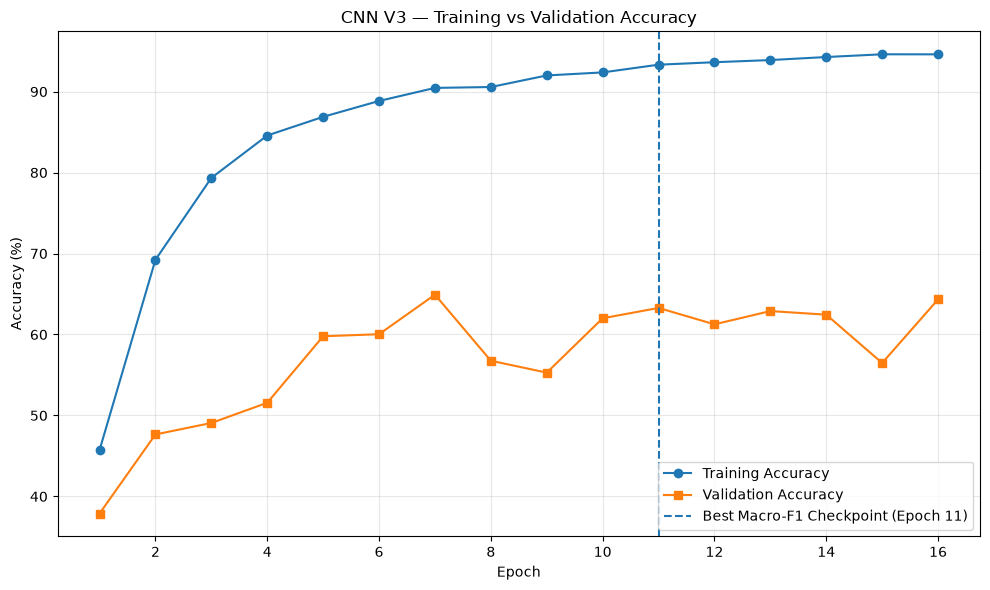

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

# Load saved training history
history = pd.read_csv(v3_history_path)

# Create figure
plt.figure(figsize=(10, 6))

# Training accuracy
plt.plot(
    history["epoch"],
    history["train_accuracy"] * 100,
    marker="o",
    label="Training Accuracy"
)

# Validation accuracy
plt.plot(
    history["epoch"],
    history["val_accuracy"] * 100,
    marker="s",
    label="Validation Accuracy"
)

# Mark best checkpoint
plt.axvline(
    x=best_epoch_v3,
    linestyle="--",
    label=f"Best Macro-F1 Checkpoint (Epoch {best_epoch_v3})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN V3 — Training vs Validation Accuracy")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
plt.savefig(
    v3_exp_dir / "training_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 21. CNN V3 — Error Analysis

Analyze predictions from the best CNN V3 checkpoint.

Objectives:
- Identify difficult classes.
- Find common classification mistakes.
- Measure performance for individual drivers.
- Identify possible improvements for future experiments.

In [24]:
import pandas as pd
import numpy as np
import torch

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# ==========================================
# 1. Load the best CNN V3 checkpoint
# ==========================================

error_model_v3 = DriverCNNV3().to(device)

error_model_v3.load_state_dict(
    torch.load(
        v3_best_path,
        map_location=device,
        weights_only=True
    )
)

error_model_v3.eval()


# ==========================================
# 2. Collect validation predictions
# ==========================================

all_true = []
all_pred = []
all_confidence = []

with torch.no_grad():

    for images, labels in v3_val_loader:

        images = images.to(device)

        outputs = error_model_v3(images)

        probabilities = torch.softmax(outputs, dim=1)

        confidence, predictions = probabilities.max(dim=1)

        all_true.extend(labels.numpy())
        all_pred.extend(predictions.cpu().numpy())
        all_confidence.extend(confidence.cpu().numpy())


# ==========================================
# 3. Create prediction DataFrame
# ==========================================

error_df_v3 = val_df.reset_index(drop=True).copy()

assert len(error_df_v3) == len(all_true)

assert np.array_equal(
    error_df_v3["classname"].str[1:].astype(int).to_numpy(),
    np.asarray(all_true)
)

error_df_v3["actual"] = [f"c{x}" for x in all_true]
error_df_v3["predicted"] = [f"c{x}" for x in all_pred]

error_df_v3["confidence"] = all_confidence

error_df_v3["correct"] = (
    error_df_v3["actual"] == error_df_v3["predicted"]
)


# ==========================================
# 4. Performance by class
# ==========================================

print("PER-CLASS CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        all_true,
        all_pred,
        labels=list(range(10)),
        target_names=[f"c{i}" for i in range(10)],
        zero_division=0
    )
)


# ==========================================
# 5. Most common mistakes
# ==========================================

mistakes_v3 = error_df_v3[
    ~error_df_v3["correct"]
]

confusions_v3 = (
    mistakes_v3
    .groupby(["actual", "predicted"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

print("\nTOP 10 CLASS CONFUSIONS")
print("=" * 50)

print(
    confusions_v3.head(10).to_string(index=False)
)


# ==========================================
# 6. Accuracy by driver
# ==========================================

driver_results_v3 = (
    error_df_v3
    .groupby("subject")
    .agg(
        images=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .sort_values("accuracy")
)

print("\nACCURACY BY DRIVER")
print("=" * 50)

print(driver_results_v3)


# ==========================================
# 7. Save analysis
# ==========================================

v3_error_dir = v3_exp_dir / "error_analysis"

v3_error_dir.mkdir(parents=True, exist_ok=True)

error_df_v3.to_csv(
    v3_error_dir / "predictions.csv",
    index=False
)

confusions_v3.to_csv(
    v3_error_dir / "class_confusions.csv",
    index=False
)

driver_results_v3.to_csv(
    v3_error_dir / "driver_accuracy.csv"
)

print("\nCNN V3 error analysis saved!")

PER-CLASS CLASSIFICATION REPORT
              precision    recall  f1-score   support

          c0       0.78      0.56      0.65       372
          c1       0.92      0.73      0.81       377
          c2       0.85      0.49      0.62       367
          c3       0.93      0.74      0.83       393
          c4       0.51      0.57      0.54       378
          c5       0.97      0.85      0.90       372
          c6       0.84      0.76      0.80       372
          c7       0.59      0.80      0.68       342
          c8       0.17      0.45      0.25       298
          c9       0.55      0.31      0.40       332

    accuracy                           0.63      3603
   macro avg       0.71      0.63      0.65      3603
weighted avg       0.73      0.63      0.66      3603


TOP 10 CLASS CONFUSIONS
actual predicted  count
    c4        c8    135
    c9        c4    118
    c2        c8     88
    c8        c7     82
    c9        c8     80
    c0        c8     77
    c2        c7

## 22. CNN V3 — Validation Confusion Matrix

Visualize classification performance across all 10 driving activities.

- Rows: Actual classes
- Columns: Predicted classes
- Diagonal: Correct predictions
- Off-diagonal: Misclassifications

Evaluate the best CNN V3 checkpoint on 3,603 validation images
from four unseen drivers.

CNN V3 — VALIDATION INFERENCE
Validation images: 3603
Accuracy: 0.6328
Macro-F1: 0.6478


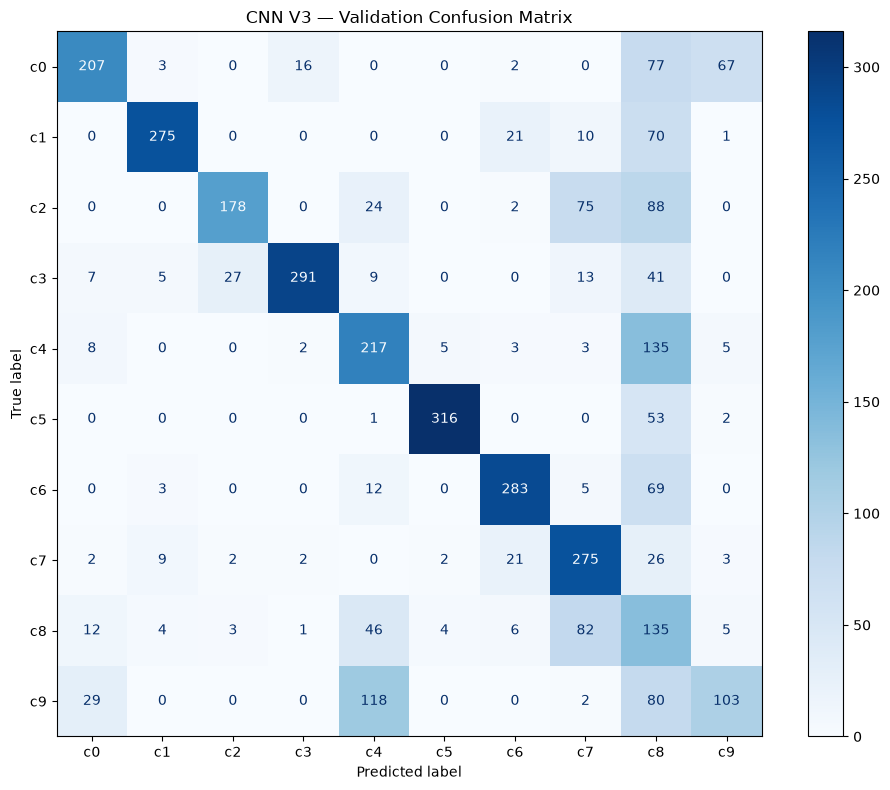

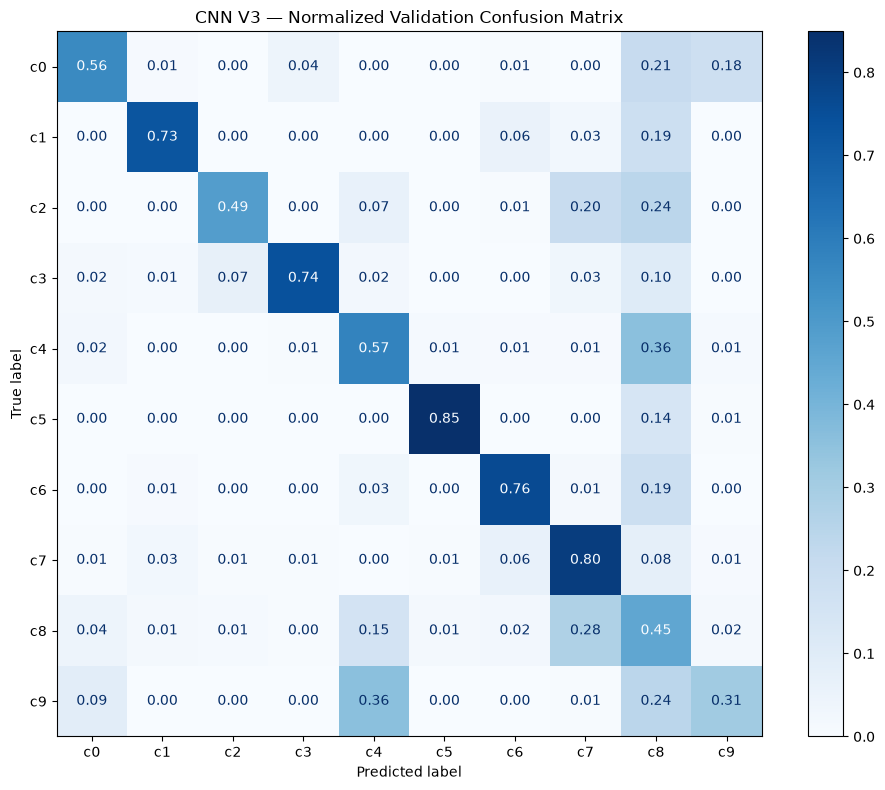

In [25]:
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. Load our best trained CNN V3
# ==========================================

model = DriverCNNV3(num_classes=10).to(device)

model.load_state_dict(
    torch.load(
        v3_best_path,
        map_location=device,
        weights_only=True
    )
)

# Switch to inference mode
model.eval()

# ==========================================
# 2. Run inference on validation images
# ==========================================

y_true = []
y_pred = []

with torch.inference_mode():

    for images, labels in v3_val_loader:

        images = images.to(device)

        # Predict using the trained CNN
        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

# ==========================================
# 3. Calculate performance
# ==========================================

accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    labels=list(range(10)),
    zero_division=0
)

print("CNN V3 — VALIDATION INFERENCE")
print("=" * 40)

print("Validation images:", len(y_true))
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")

# ==========================================
# 4. Confusion Matrix — Counts
# ==========================================

class_names = [f"c{i}" for i in range(10)]

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(10)),
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("CNN V3 — Validation Confusion Matrix")

plt.tight_layout()

plt.savefig(
    v3_error_dir / "inference_confusion_matrix.png",
    dpi=300
)

plt.show()

# ==========================================
# 5. Normalized Confusion Matrix
# ==========================================

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(10)),
    display_labels=class_names,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=ax
)

ax.set_title("CNN V3 — Normalized Validation Confusion Matrix")

plt.tight_layout()

plt.savefig(
    v3_error_dir / "inference_confusion_matrix_normalized.png",
    dpi=300
)

plt.show()

## 24. CNN V3 — Visual Error Analysis

Inspect validation images that CNN V3 classified incorrectly.

Focus on:
- c4 → c8: Phone (left) confused with hair/makeup
- c9 → c4: Talking to passenger confused with phone (left)
- c8 → c7: Hair/makeup confused with reaching behind

Goal: Identify visual patterns responsible for misclassification.

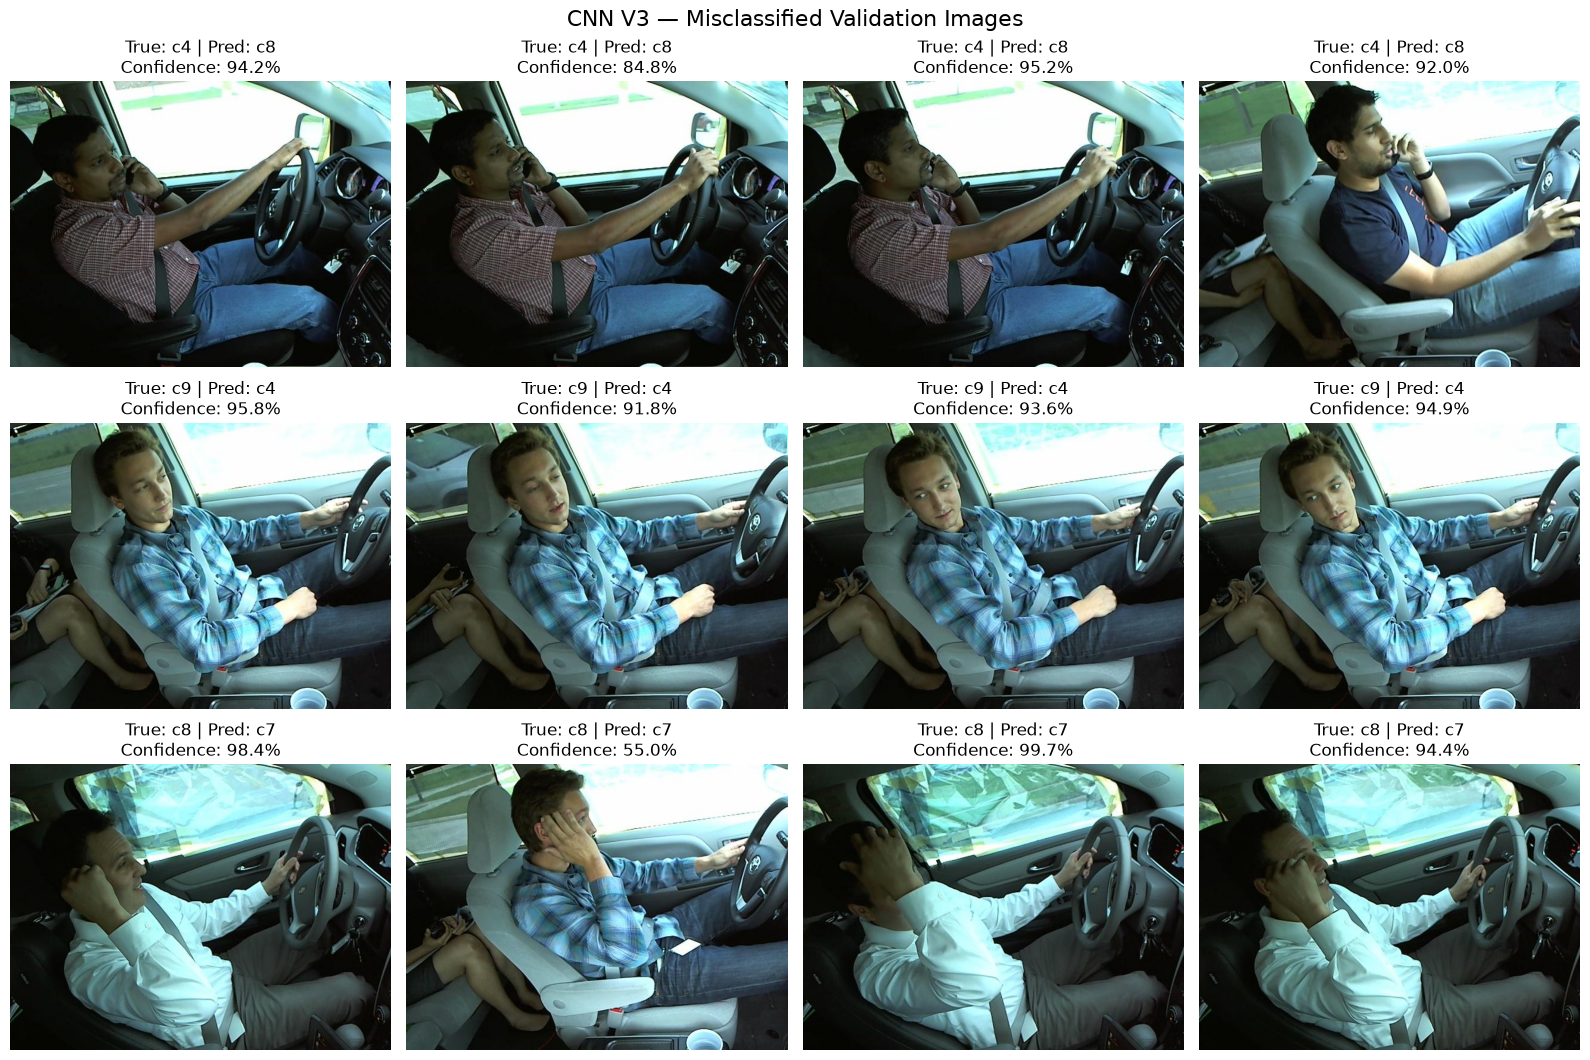

In [26]:
from PIL import Image
import matplotlib.pyplot as plt

# Most interesting confusion pairs
confusion_pairs = [
    ("c4", "c8"),
    ("c9", "c4"),
    ("c8", "c7")
]

fig, axes = plt.subplots(3, 4, figsize=(16, 11))

for row_idx, (actual, predicted) in enumerate(confusion_pairs):

    # Select misclassified validation images
    examples = error_df_v3[
        (error_df_v3["actual"] == actual) &
        (error_df_v3["predicted"] == predicted)
    ]

    # Choose 4 reproducible examples
    examples = examples.sample(
        n=min(4, len(examples)),
        random_state=42
    )

    for col_idx, ax in enumerate(axes[row_idx]):

        if col_idx >= len(examples):
            ax.axis("off")
            continue

        row = examples.iloc[col_idx]

        # Load original image
        image_path = (
            image_root /
            row["classname"] /
            row["img"]
        )

        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"True: {actual} | Pred: {predicted}\n"
            f"Confidence: {row['confidence']:.1%}"
        )

        ax.axis("off")

plt.suptitle(
    "CNN V3 — Misclassified Validation Images",
    fontsize=16
)

plt.tight_layout()

# Save for presentation
plt.savefig(
    v3_error_dir / "error_examples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# Investigate which drivers produce the most frequent mistakes

pairs = [
    ("c4", "c8"),
    ("c9", "c4"),
    ("c8", "c7")
]

for actual, predicted in pairs:

    errors = error_df_v3[
        (error_df_v3["actual"] == actual) &
        (error_df_v3["predicted"] == predicted)
    ]

    print(f"\n{actual} → {predicted}")
    print("Total mistakes:", len(errors))

    print(
        errors.groupby("subject")
        .size()
        .sort_values(ascending=False)
        .to_string()
    )


c4 → c8
Total mistakes: 135
subject
p075    85
p014    50

c9 → c4
Total mistakes: 118
subject
p016    118

c8 → c7
Total mistakes: 82
subject
p047    81
p016     1


In [29]:
# Calculate confusion rates within each driver's actual class

pairs = [
    ("c4", "c8"),
    ("c9", "c4"),
    ("c8", "c7")
]

for actual, predicted in pairs:

    print(f"\n{actual} → {predicted}")
    print("=" * 45)

    # All validation images belonging to the actual class
    class_images = error_df_v3[
        error_df_v3["actual"] == actual
    ]

    # Number of images of this class for each driver
    total_by_driver = class_images.groupby("subject").size()

    # Number misclassified as the target class
    errors_by_driver = (
        class_images[
            class_images["predicted"] == predicted
        ]
        .groupby("subject")
        .size()
    )

    # Calculate error percentage per driver
    comparison = pd.DataFrame({
        "total_images": total_by_driver,
        "mistakes": errors_by_driver
    }).fillna(0)

    comparison["error_rate"] = (
        comparison["mistakes"] /
        comparison["total_images"] * 100
    )

    print(comparison.round(2).to_string())


c4 → c8
         total_images  mistakes  error_rate
subject                                    
p014              103      50.0       48.54
p016              104       0.0        0.00
p047               82       0.0        0.00
p075               89      85.0       95.51

c9 → c4
         total_images  mistakes  error_rate
subject                                    
p014               52       0.0        0.00
p016              120     118.0       98.33
p047               83       0.0        0.00
p075               77       0.0        0.00

c8 → c7
         total_images  mistakes  error_rate
subject                                    
p014               38       0.0        0.00
p016               99       1.0        1.01
p047               82      81.0       98.78
p075               79       0.0        0.00
